# What Drives the Price of a Car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, I explore a Kaggle dataset of 426K used-car listings to understand what factors make a car more or less expensive, and turn that into clear recommendations for a used car dealership about what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>

The analysis follows the six CRISP-DM phases: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment.

## 1. Business Understanding

**Business objective.** A used car dealership wants to fine-tune its inventory. It needs to know which characteristics of a used car make it more or less expensive, so it can stock vehicles that customers value and price them appropriately.

**Data problem definition.** This is a **supervised regression** task. The target is the listing `price`, and the features are the vehicle's attributes (age, mileage, manufacturer, condition, fuel type, drive train, body type, and so on). We have two goals:

- **Explain:** identify and quantify the attributes that drive price (via interpretable linear models and their coefficients).
- **Predict:** estimate price accurately enough that the drivers we identify are trustworthy.

**Success criteria.** The models should clearly beat a naive baseline (always predicting the average price) on held-out data. The findings should also translate into concrete inventory recommendations.

## 2. Data Understanding

### 2.1 Imports and settings

In [1]:
# Core data libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Consistent plot styling and reproducibility
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

### 2.2 Load the data

In [2]:
cars = pd.read_csv('data/vehicles.csv')
print(f'Rows: {cars.shape[0]:,}   Columns: {cars.shape[1]}')
cars.head()

Rows: 426,880   Columns: 18


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


### 2.3 Structure, types, and missing values

In [3]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-null  object 
dtypes: f

In [4]:
# Percentage of missing values per column, sorted high to low
missing_pct = (cars.isna().mean() * 100).sort_values(ascending=False).round(1)
missing_pct.to_frame('% missing')

,% missing
size,71.8
cylinders,41.6
condition,40.8
VIN,37.7
drive,30.6
paint_color,30.5
type,21.8
manufacturer,4.1
title_status,1.9
model,1.2


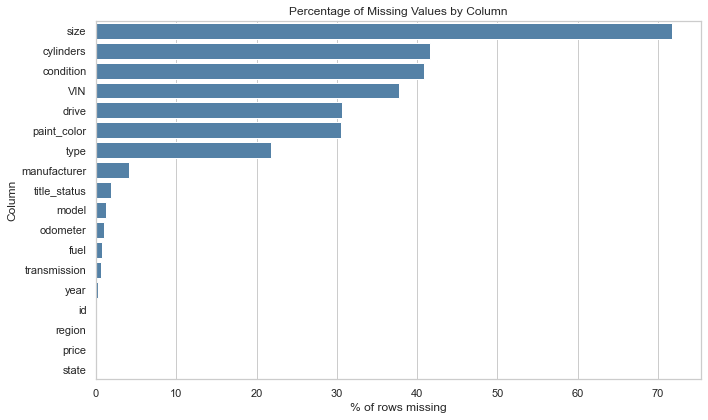

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color='steelblue', ax=ax)
ax.set_title('Percentage of Missing Values by Column')
ax.set_xlabel('% of rows missing')
ax.set_ylabel('Column')
plt.tight_layout()
plt.show()

### 2.4 Numeric summary and the target variable

In [6]:
cars[['price', 'year', 'odometer']].describe().round(0)

,price,year,odometer
count,4.268800e+05,425675.0,422480.0
mean,7.519900e+04,2011.0,98043.0
std,1.218228e+07,9.0,213882.0
min,0.000000e+00,1900.0,0.0
25%,5.900000e+03,2008.0,37704.0
50%,1.395000e+04,2013.0,85548.0
75%,2.648600e+04,2017.0,133542.0
max,3.736929e+09,2022.0,10000000.0


In [7]:
# How many listings have implausible prices?
print(f"Listings priced at $0:        {(cars['price'] == 0).sum():,}")
print(f"Listings under $1,000:        {(cars['price'] < 1_000).sum():,}")
print(f"Listings over $100,000:       {(cars['price'] > 100_000).sum():,}")
print(f"Maximum listed price:         ${cars['price'].max():,.0f}")

Listings priced at $0:        32,895
Listings under $1,000:        46,315
Listings over $100,000:       655
Maximum listed price:         $3,736,928,711


In [8]:
# Cardinality of the text columns: very high counts are hard to use directly
cars.select_dtypes('object').nunique().sort_values(ascending=False).to_frame('unique values')

,unique values
VIN,118246
model,29649
region,404
state,51
manufacturer,42
type,13
paint_color,12
cylinders,8
condition,6
title_status,6


**Observations from data understanding**

- `price` contains many **$0 placeholder listings** and a handful of absurd values in the billions. These are data-entry artifacts, not real prices, and must be filtered out.
- `county` is essentially empty, and `size` is missing for most rows. `condition`, `cylinders`, `VIN`, `drive`, and `paint_color` also have substantial gaps.
- `id` and `VIN` are identifiers with no predictive meaning.
- `model` has tens of thousands of free-text values (for example "f-150", "F150 XLT", "f150 supercrew"), which makes it impractical to one-hot encode without extensive cleaning. `region` also has hundreds of values that overlap with `state`.
- `year` and `odometer` have outliers (antique cars, odometer readings of millions of miles).

## 3. Data Preparation

### 3.1 Drop uninformative columns

In [9]:
# Identifiers, near-empty columns, and high-cardinality text we will not model.
# errors='ignore' lets this cell run on either version of the Kaggle file.
cols_to_drop = ['id', 'VIN', 'county', 'size', 'region', 'model',
                'url', 'region_url', 'image_url', 'description',
                'lat', 'long', 'posting_date']
df = cars.drop(columns=cols_to_drop, errors='ignore').copy()
df.columns.tolist()

['price',
 'year',
 'manufacturer',
 'condition',
 'cylinders',
 'fuel',
 'odometer',
 'title_status',
 'transmission',
 'drive',
 'type',
 'paint_color',
 'state']

### 3.2 Filter implausible values

The thresholds are chosen to keep ordinary dealer-lot vehicles:

- **Price between \$1,000 and \$100,000.** Below that range are placeholders and parts cars. Above it are typos and exotic cars outside a typical dealer's inventory.
- **Model year 1990 or later.** Older cars are collectibles priced on different logic.
- **Odometer under 400,000 miles.**

In [10]:
rows_before = len(df)

df = df[df['price'].between(1_000, 100_000)]
df = df[df['year'] >= 1990]
df = df[df['odometer'].between(0, 400_000)]
df = df.drop_duplicates()

print(f'Rows before: {rows_before:,}')
print(f'Rows after:  {len(df):,}  ({len(df) / rows_before:.0%} retained)')

Rows before: 426,880
Rows after:  254,278  (60% retained)


### 3.3 Feature engineering

- **`age`** replaces `year`. It is more interpretable ("each additional year of age...") and measured relative to the most recent model year in the data.
- **`log_price`** is the modeling target. Prices are strongly right-skewed. Modeling the log makes the relationship with age and mileage closer to linear, and it lets coefficients be read as **percentage** effects on price.

In [11]:
reference_year = int(df['year'].max())
df['age'] = reference_year - df['year']
df['log_price'] = np.log(df['price'])

df = df.drop(columns='year')
df[['price', 'log_price', 'age', 'odometer']].describe().round(2)

,price,log_price,age,odometer
count,254278.00,254278.00,254278.00,254278.00
mean,17972.24,9.47,10.31,98289.30
std,13936.35,0.86,6.06,64487.87
min,1000.00,6.91,0.00,0.00
25%,6995.00,8.85,5.00,43000.00
50%,14395.00,9.57,9.00,94213.00
75%,25990.00,10.17,14.00,141500.00
max,100000.00,11.51,32.00,400000.00


In [12]:
# Categorical features: missing values become an explicit 'unknown' level,
# because "seller didn't state the condition" may itself carry information.
categorical_features = ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status',
                        'transmission', 'drive', 'type', 'paint_color', 'state']
numeric_features = ['age', 'odometer']

df[categorical_features] = df[categorical_features].fillna('unknown')
df = df.dropna(subset=numeric_features)
print(f'Modeling dataset: {df.shape[0]:,} rows')

Modeling dataset: 254,278 rows


### 3.4 Exploratory visualizations

#### Distribution of the target

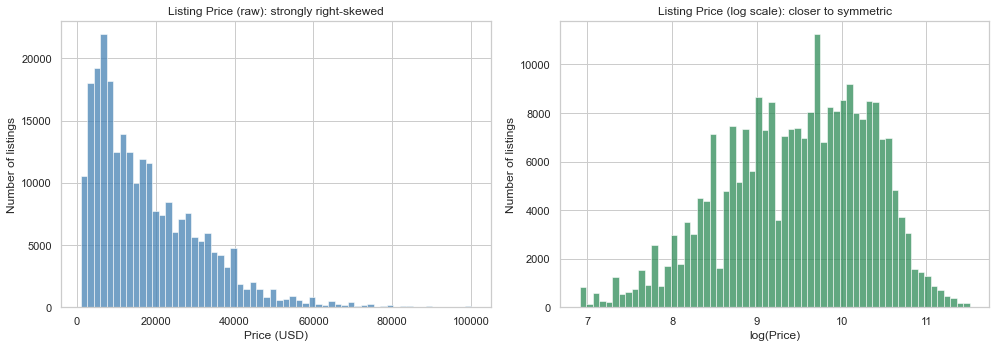

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['price'], bins=60, color='steelblue', ax=axes[0])
axes[0].set_title('Listing Price (raw): strongly right-skewed')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Number of listings')

sns.histplot(df['log_price'], bins=60, color='seagreen', ax=axes[1])
axes[1].set_title('Listing Price (log scale): closer to symmetric')
axes[1].set_xlabel('log(Price)')
axes[1].set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

#### Continuous drivers: age and mileage

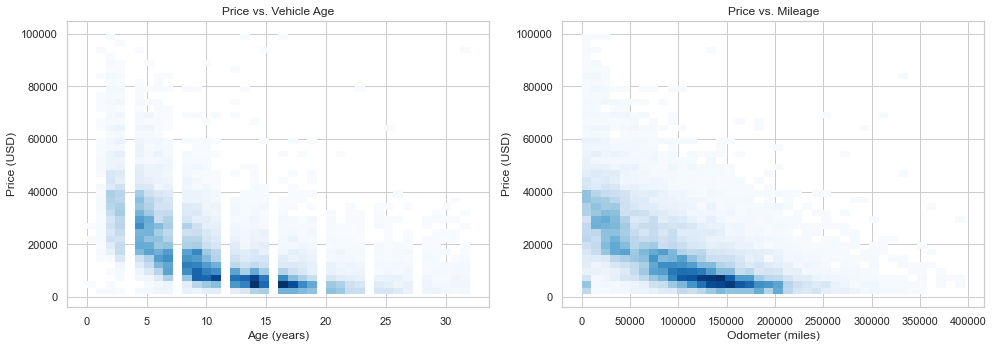

In [14]:
# Sample for plotting speed; density plots avoid overplotting 300K points
plot_sample = df.sample(20_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=plot_sample, x='age', y='price', bins=40, cmap='Blues', ax=axes[0])
axes[0].set_title('Price vs. Vehicle Age')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Price (USD)')

sns.histplot(data=plot_sample, x='odometer', y='price', bins=40, cmap='Blues', ax=axes[1])
axes[1].set_title('Price vs. Mileage')
axes[1].set_xlabel('Odometer (miles)')
axes[1].set_ylabel('Price (USD)')

plt.tight_layout()
plt.show()

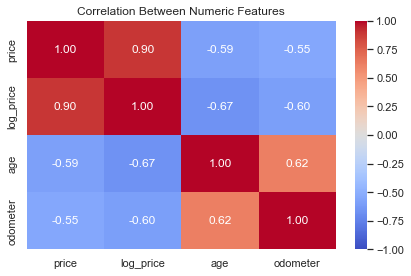

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(df[['price', 'log_price', 'age', 'odometer']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Between Numeric Features')
plt.tight_layout()
plt.show()

#### Categorical drivers

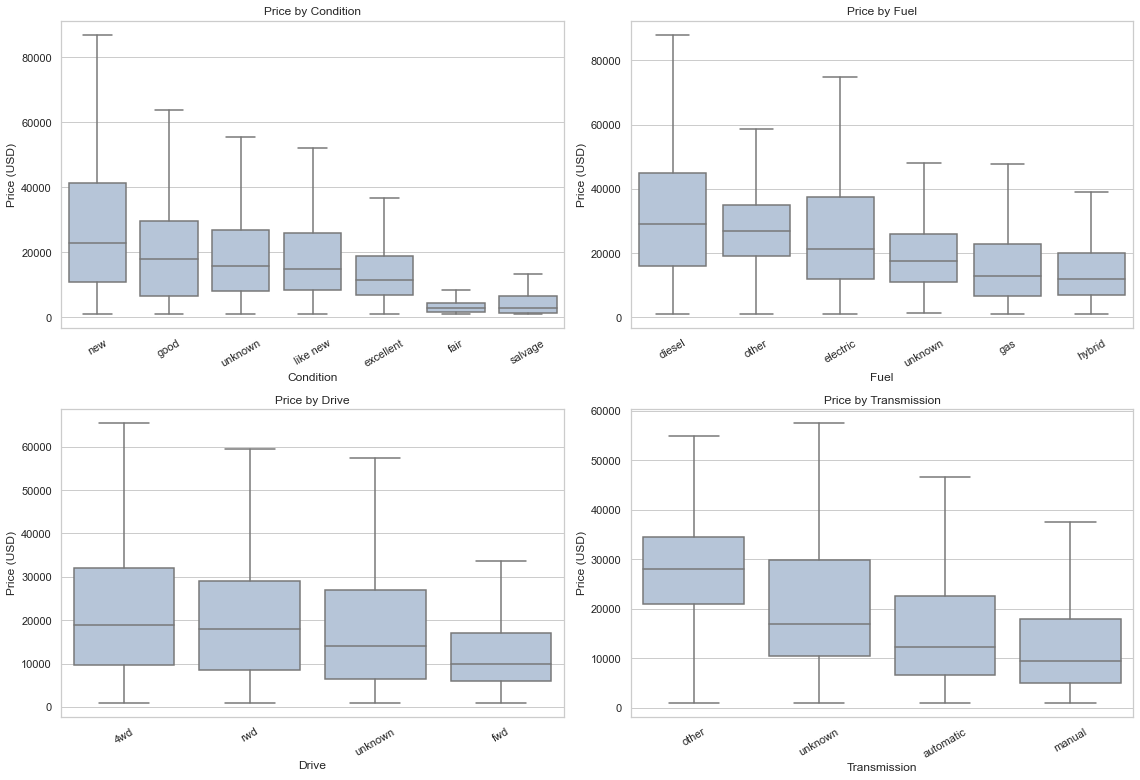

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
cat_plots = [('condition', axes[0, 0]), ('fuel', axes[0, 1]),
             ('drive', axes[1, 0]), ('transmission', axes[1, 1])]

for col, ax in cat_plots:
    order = df.groupby(col)['price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y='price', order=order, showfliers=False,
                color='lightsteelblue', ax=ax)
    ax.set_title(f'Price by {col.replace("_", " ").title()}')
    ax.set_xlabel(col.replace('_', ' ').title())
    ax.set_ylabel('Price (USD)')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

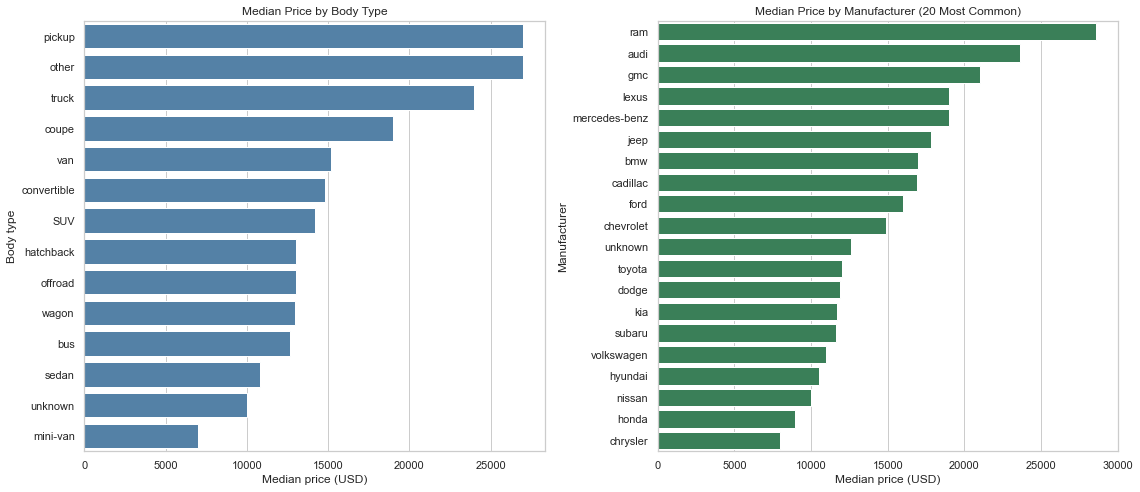

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

type_median = df.groupby('type')['price'].median().sort_values(ascending=False)
sns.barplot(x=type_median.values, y=type_median.index, color='steelblue', ax=axes[0])
axes[0].set_title('Median Price by Body Type')
axes[0].set_xlabel('Median price (USD)')
axes[0].set_ylabel('Body type')

# Top 20 manufacturers by listing count, ranked by median price
top_makes = df['manufacturer'].value_counts().head(20).index
make_median = (df[df['manufacturer'].isin(top_makes)]
               .groupby('manufacturer')['price'].median().sort_values(ascending=False))
sns.barplot(x=make_median.values, y=make_median.index, color='seagreen', ax=axes[1])
axes[1].set_title('Median Price by Manufacturer (20 Most Common)')
axes[1].set_xlabel('Median price (USD)')
axes[1].set_ylabel('Manufacturer')

plt.tight_layout()
plt.show()

**EDA takeaways**

- Price falls steadily with **age** and **mileage**, which are the two strongest continuous signals. Their negative correlation with log price is visible in the heatmap and density plots.
- **Diesel**, **4WD**, and **pickup/truck** body types have noticeably higher median prices than gas, front-wheel-drive, and sedan/hatchback vehicles.
- Listings in **"fair"** or **"salvage"** condition sell for much less than the other condition levels.
- These are raw comparisons. Trucks are also more often diesel and 4WD, so the models below are needed to separate each attribute's own effect.

## 4. Modeling

### 4.1 Train/test split

We hold out 20% of the data as a final test set. All hyperparameter tuning uses 5-fold cross-validation on the training set only, so the test score is an honest estimate of performance on new listings.

In [18]:
X = df[numeric_features + categorical_features]
y = df['log_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f'Training rows: {len(X_train):,}   Test rows: {len(X_test):,}')

Training rows: 203,422   Test rows: 50,856


### 4.2 Preprocessing pipeline

A `ColumnTransformer` applies the right transformation to each feature type. Wrapping it in a `Pipeline` with the model means the scaler and encoder are fit **only on training folds** during cross-validation, which prevents data leakage.

- **Numeric (`age`, `odometer`):** impute median, then standardize so regularization treats features fairly.
- **Categorical:** one-hot encode. `handle_unknown='ignore'` protects against categories that appear only in the test set.

In [19]:
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

### 4.3 Evaluation metric

- **Primary metric: RMSE**, computed during cross-validation on the log-price scale. RMSE on log price is roughly the typical *percentage* error, so it treats a \$2,000 miss on a \$10,000 car as more serious than the same miss on a \$60,000 truck, which matches how pricing errors actually hurt a dealer.
- **Reported for the business audience:** **MAE in dollars** on the test set (after converting predictions back with `exp`). It answers the question "on average, how far off is the predicted price?" and is less distorted by a few extreme listings than RMSE in dollars.
- **R²** is also reported as the share of variation in log price the model explains.

In [20]:
results = []

def evaluate(model, name):
    """Score a fitted model on the test set and store the results."""
    pred_log = model.predict(X_test)
    pred_dollars = np.exp(pred_log)
    actual_dollars = np.exp(y_test)
    scores = {
        'model': name,
        'test_RMSE_log': np.sqrt(mean_squared_error(y_test, pred_log)),
        'test_R2_log': r2_score(y_test, pred_log),
        'test_MAE_$': mean_absolute_error(actual_dollars, pred_dollars),
        'test_RMSE_$': np.sqrt(mean_squared_error(actual_dollars, pred_dollars)),
    }
    results.append(scores)
    return pd.Series(scores)

### 4.4 Baseline: always predict the average

In [21]:
baseline = Pipeline([('prep', preprocessor), ('model', DummyRegressor(strategy='mean'))])
baseline.fit(X_train, y_train)
evaluate(baseline, 'Baseline (mean)')

model            Baseline (mean)
test_RMSE_log           0.859451
test_R2_log            -0.000001
test_MAE_$          10641.208376
test_RMSE_$          14845.43904
dtype: object

### 4.5 Model 1: Ordinary least squares linear regression

In [22]:
linreg = Pipeline([('prep', preprocessor), ('model', LinearRegression())])
linreg.fit(X_train, y_train)
evaluate(linreg, 'Linear Regression')

model            Linear Regression
test_RMSE_log             0.430375
test_R2_log               0.749243
test_MAE_$             4670.781188
test_RMSE_$            7744.215202
dtype: object

### 4.6 Model 2: Ridge regression with grid search

Ridge adds an L2 penalty that shrinks coefficients. This stabilizes them when one-hot columns are correlated (for example, `fuel=diesel` and `type=pickup`). We search over the penalty strength `alpha` with 5-fold CV.

In [23]:
ridge_pipe = Pipeline([('prep', preprocessor), ('model', Ridge())])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={'model__alpha': np.logspace(-2, 3, 12)},
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)

print(f"Best alpha: {ridge_grid.best_params_['model__alpha']:.3f}")
print(f'Best CV RMSE (log): {-ridge_grid.best_score_:.4f}')
evaluate(ridge_grid.best_estimator_, 'Ridge')

Best alpha: 0.010
Best CV RMSE (log): 0.4305


model                  Ridge
test_RMSE_log       0.430629
test_R2_log         0.748948
test_MAE_$       4675.462993
test_RMSE_$      7740.149842
dtype: object

### 4.7 Model 3: Lasso regression with grid search

Lasso's L1 penalty can drive weak coefficients to exactly zero, which acts as automatic feature selection and tells us which attributes do **not** matter. Lasso is slower to fit, so the grid search runs on a 50,000-row sample of the training data. The final model is then refit on the full training set.

In [24]:
lasso_pipe = Pipeline([('prep', preprocessor), ('model', Lasso(max_iter=5_000))])
lasso_grid = GridSearchCV(
    lasso_pipe,
    param_grid={'model__alpha': np.logspace(-5, -1, 9)},
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1,
)

# Tune on a sample for speed
tune_idx = X_train.sample(min(50_000, len(X_train)), random_state=RANDOM_STATE).index
lasso_grid.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
best_lasso_alpha = lasso_grid.best_params_['model__alpha']
print(f'Best alpha: {best_lasso_alpha:.5f}')
print(f'Best CV RMSE (log): {-lasso_grid.best_score_:.4f}')

# Refit the best configuration on all training data
lasso_final = lasso_grid.best_estimator_.fit(X_train, y_train)
n_zero = (lasso_final.named_steps['model'].coef_ == 0).sum()
n_total = lasso_final.named_steps['model'].coef_.size
print(f'Coefficients set to zero: {n_zero} of {n_total}')
evaluate(lasso_final, 'Lasso')

Best alpha: 0.00001
Best CV RMSE (log): 0.4319
Coefficients set to zero: 9 of 159


model                  Lasso
test_RMSE_log       0.430344
test_R2_log         0.749279
test_MAE_$        4669.76042
test_RMSE_$      7732.179954
dtype: object

### 4.8 Model 4: Ridge with polynomial features on age and mileage

The EDA shows that depreciation is **not** a straight line. Cars lose value fastest in their first few years. Adding squared and cubed terms for `age` and `odometer` lets the model capture this curve. The grid search tunes both the polynomial degree and `alpha` together.

In [25]:
poly_numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scale', StandardScaler()),
])

poly_preprocessor = ColumnTransformer([
    ('num', poly_numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

poly_pipe = Pipeline([('prep', poly_preprocessor), ('model', Ridge())])
poly_grid = GridSearchCV(
    poly_pipe,
    param_grid={
        'prep__num__poly__degree': [1, 2, 3],
        'model__alpha': np.logspace(-1, 2, 6),
    },
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1,
)
poly_grid.fit(X_train, y_train)

print(f'Best parameters: {poly_grid.best_params_}')
print(f'Best CV RMSE (log): {-poly_grid.best_score_:.4f}')
evaluate(poly_grid.best_estimator_, 'Polynomial Ridge')

Best parameters: {'model__alpha': 0.3981071705534972, 'prep__num__poly__degree': 3}
Best CV RMSE (log): 0.4154


model            Polynomial Ridge
test_RMSE_log            0.415393
test_R2_log              0.766398
test_MAE_$            4578.382706
test_RMSE_$           7631.335072
dtype: object

## 5. Evaluation

### 5.1 Model comparison

In [26]:
results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,test_RMSE_log,test_R2_log,test_MAE_$,test_RMSE_$
model,,,,
Baseline (mean),0.859,-0.000,10641.208,14845.439
Linear Regression,0.430,0.749,4670.781,7744.215
Ridge,0.431,0.749,4675.463,7740.150
Lasso,0.430,0.749,4669.760,7732.180
Polynomial Ridge,0.415,0.766,4578.383,7631.335


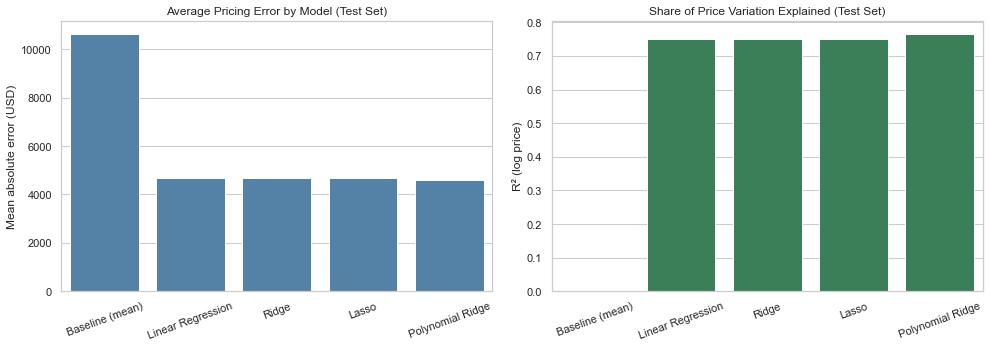

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=results_df.index, y=results_df['test_MAE_$'], color='steelblue', ax=axes[0])
axes[0].set_title('Average Pricing Error by Model (Test Set)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mean absolute error (USD)')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(x=results_df.index, y=results_df['test_R2_log'], color='seagreen', ax=axes[1])
axes[1].set_title('Share of Price Variation Explained (Test Set)')
axes[1].set_xlabel('')
axes[1].set_ylabel('R² (log price)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Interpreting the metrics**

- The baseline's MAE of about **\$10,600** is the error from quoting the average price for every car. The best model (Polynomial Ridge) cuts this to about **\$4,600**, a **57% reduction**.
- An R² of **0.77** means the model explains about 77% of the variation in (log) listing prices using only the listed attributes. The rest comes from factors not in the data, such as trim level, accident history, options, and negotiation.
- Linear regression, Ridge, and Lasso perform almost identically. With about 200K training rows and 159 features, overfitting is not a problem, which is why the grid search picked small penalties (Lasso chose the smallest `alpha` tested). The regularized models' value here is more stable coefficients, not better accuracy.
- The **polynomial model** is the most accurate because the best degree (3) captures the curved depreciation pattern in age and mileage. Its improvement is modest, so the simpler Ridge model is used below for interpreting coefficients.

### 5.2 What drives price? Interpreting the coefficients

We interpret the **Ridge** model. Because the target is log price, a coefficient **b** on a one-hot feature means that attribute changes price by approximately **(e^b − 1) × 100%**, relative to a comparable car in the dropped reference category. It is measured with all other features held constant. For the scaled numeric features, the effect is per one standard deviation.

In [28]:
best_ridge = ridge_grid.best_estimator_
feature_names = best_ridge.named_steps['prep'].get_feature_names_out()
coefs = pd.DataFrame({
    'feature': feature_names,
    'coef': best_ridge.named_steps['model'].coef_,
})
coefs['pct_effect_on_price'] = (np.exp(coefs['coef']) - 1) * 100
coefs['feature'] = coefs['feature'].str.replace('num__', '').str.replace('cat__', '')

# Exclude state dummies from the chart: they reflect regional markets, not the car itself
car_coefs = coefs[~coefs['feature'].str.startswith('state_')]
top_coefs = pd.concat([car_coefs.nlargest(12, 'coef'), car_coefs.nsmallest(12, 'coef')])

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['seagreen' if v > 0 else 'indianred' for v in top_coefs['pct_effect_on_price']]
ax.barh(top_coefs['feature'], top_coefs['pct_effect_on_price'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Largest Estimated Effects on Price (Ridge, all else equal)')
ax.set_xlabel('Approximate % change in price')
ax.set_ylabel('')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

AttributeError: 'ColumnTransformer' object has no attribute 'get_feature_names_out'

In [ ]:
# Effect of the continuous features in real-world units.
# The coefficient is per standard deviation, so convert to per-year and per-10k-miles.
scaler = best_ridge.named_steps['prep'].named_transformers_['num'].named_steps['scale']
std_by_feature = dict(zip(numeric_features, scaler.scale_))

for feat, unit, unit_size in [('age', 'year of age', 1), ('odometer', '10,000 miles', 10_000)]:
    b = coefs.loc[coefs['feature'] == feat, 'coef'].iloc[0]
    per_unit = b / std_by_feature[feat] * unit_size
    print(f'Each additional {unit}: {(np.exp(per_unit) - 1) * 100:+.1f}% change in price')

### 5.3 Permutation importance

Coefficients show the direction and size of individual categories. **Permutation importance** answers a different question: *how much worse do predictions get if we scramble one original feature?* It ranks whole attributes (for example, all of `manufacturer`) on a common scale. We compute it on a 5,000-row test sample for speed.

In [ ]:
perm_sample = X_test.sample(5_000, random_state=RANDOM_STATE)
perm = permutation_importance(
    best_ridge, perm_sample, y_test.loc[perm_sample.index],
    scoring='neg_root_mean_squared_error', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance = (pd.DataFrame({'feature': perm_sample.columns,
                            'importance': perm.importances_mean,
                            'std': perm.importances_std})
              .sort_values('importance', ascending=False))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=importance, x='importance', y='feature', color='steelblue', ax=ax)
ax.set_title('Which Attributes Matter Most? (Permutation Importance)')
ax.set_xlabel('Increase in prediction error when feature is shuffled (RMSE, log price)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Deployment: Findings for Used Car Dealers

The numbers below are computed directly from the fitted Ridge model, so they update automatically if the data or model changes.

In [ ]:
from IPython.display import Markdown, display

# Look up coefficients by feature name (e.g. 'fuel_diesel', 'type_pickup')
coef = dict(zip(coefs['feature'], coefs['coef']))

def pct_diff(a, b):
    """Approximate % price difference of category a vs. category b, all else equal."""
    if a not in coef or b not in coef:
        return float('nan')
    return (np.exp(coef[a] - coef[b]) - 1) * 100

# Continuous features: convert per-standard-deviation coefficients to real units
age_pct = (np.exp(coef['age'] / std_by_feature['age']) - 1) * 100
miles_pct = (np.exp(coef['odometer'] / std_by_feature['odometer'] * 10_000) - 1) * 100

# Brand effects among the 20 most common manufacturers
common_makes = df.loc[df['manufacturer'] != 'unknown', 'manufacturer'].value_counts().head(20).index
brand_coefs = pd.Series({m: coef.get(f'manufacturer_{m}') for m in common_makes}).dropna()
brand_pct = (np.exp(brand_coefs - brand_coefs.median()) - 1) * 100
high_brands = ', '.join(brand_pct.nlargest(3).index.str.title())
low_brands = ', '.join(brand_pct.nsmallest(3).index.str.title())

# Best model's typical error in dollars
model_scores = results_df.drop(index='Baseline (mean)')
best_model = model_scores['test_MAE_$'].idxmin()
best_mae = model_scores['test_MAE_$'].min()
baseline_mae = results_df.loc['Baseline (mean)', 'test_MAE_$']

report = f"""
### Key findings

1. **Age and mileage:** each additional year of age changes price by about **{age_pct:+.1f}%**, and every 10,000 extra miles by about **{miles_pct:+.1f}%**.
2. **Body type and drive:** pickups list **{pct_diff('type_pickup', 'type_sedan'):+.0f}%** and trucks **{pct_diff('type_truck', 'type_sedan'):+.0f}%** vs. comparable sedans; 4WD is **{pct_diff('drive_4wd', 'drive_fwd'):+.0f}%** vs. front-wheel drive.
3. **Engine:** diesel vehicles list **{pct_diff('fuel_diesel', 'fuel_gas'):+.0f}%** vs. comparable gas vehicles, and 8-cylinder engines **{pct_diff('cylinders_8 cylinders', 'cylinders_4 cylinders'):+.0f}%** vs. 4-cylinder.
4. **Condition and title:** a car in "fair" condition lists **{pct_diff('condition_fair', 'condition_good'):+.0f}%** vs. one in "good" condition, while "excellent" ({pct_diff('condition_excellent', 'condition_good'):+.0f}%) and "like new" ({pct_diff('condition_like new', 'condition_good'):+.0f}%) add little beyond "good". A salvage title is **{pct_diff('title_status_salvage', 'title_status_clean'):+.0f}%** and a rebuilt title **{pct_diff('title_status_rebuilt', 'title_status_clean'):+.0f}%** vs. clean.
5. **Brand:** among common makes, **{high_brands}** list highest relative to comparable vehicles, and **{low_brands}** list lowest.

**Pricing accuracy:** the best model ({best_model}) is off by about **${best_mae:,.0f}** on average, compared with **${baseline_mae:,.0f}** for simply quoting the average price.
"""
display(Markdown(report))

### What this means for your inventory

After cleaning, the analysis covered about 254,000 listings. The model explains roughly three quarters of the differences in listing prices, and its typical error is about \$4,600.

**Age and mileage come first.** They are by far the most important factors. A car loses about 7% of its value for each year of age and about 4% for every 10,000 miles, and value drops fastest in the early years. No other attribute comes close.

**Trucks, 4WD, and bigger engines earn a premium.** With age and mileage held equal, pickups and trucks list about 40% above comparable sedans, and 4WD vehicles about 30% above front-wheel drive. Diesel and 8-cylinder engines add substantial value as well. Much of this reflects heavy-duty work trucks, so it is a truck-market effect rather than a reason to stock diesel sedans.

**"Fair" condition and branded titles are costly.** A car described as "fair" lists about 40% below one in "good" condition, but moving from "good" to "excellent" or "like new" adds only about 10%. Salvage and rebuilt titles cut prices by roughly 20–30%.

**Brand matters, but less.** Lexus, Audi, Mercedes-Benz, and Toyota hold their value best among common makes. Chrysler, Kia, Hyundai, and Nissan list lowest for otherwise similar cars. Paint color has almost no effect on price.

### Recommendations

- **Prioritize late-model, lower-mileage vehicles.** Age and mileage drive price more than anything else, so these cars command the highest prices.
- **Expand truck, 4WD, and diesel inventory**, especially in regions where they are popular.
- **Recondition cars to at least "good" condition.** Getting a car out of "fair" is where reconditioning pays off most, while polishing a "good" car to "excellent" adds only about 10%.
- **Be cautious with salvage and rebuilt titles.** Buy them only when the acquisition discount exceeds the roughly 20–30% price penalty.
- **Favor brands that hold value** (Lexus, Toyota, Audi, Mercedes-Benz) when prices are comparable, and don't pay extra for paint color.
- **Use the model as a pricing sanity check, not a replacement for an appraiser.** Its typical error is about \$4,600.

### Next steps

- **Add the `model` field** after standardizing its spelling (for example, grouping all F-150 variants). Trim and model likely explain much of the remaining variation.
- **Try non-linear models** such as random forests or gradient boosting to improve accuracy, keeping the linear model for explanation.
- **Build region-specific views.** The value of trucks and 4WD differs by state and climate.
- **Refresh with recent data.** Used-car prices shifted sharply in 2021–2023, so the model should be retrained regularly.